# Dynamical structure factor from the local response

This notebook reads `response_pm.csv`, which contains $\langle\psi_0|S^+_j(t)S^-_{j_0}|\psi_0\rangle$ for each site and time, and `sites.dat`. It Fourier-transforms the spatially resolved response using $e^{-iq(r_j-r_{j_0})}$ and the positive-frequency convention $e^{+i\omega t}$, then plots the real part of $S^{+-}(q,\omega)$.

The displayed frequency grid can be made dense, but that does not improve the physical resolution. With a time window of length $T$, spectral features are resolved only on the scale $2\pi/T$; increase the evolution duration for finer resolution.


For the isotropic nearest-neighbor spin-1/2 Heisenberg chain (J=1), the overlays show the exact two-spinon continuum boundaries and the linear spin-wave dispersion. They are analytical references, not fits to the finite-time data.

In [7]:
using DelimitedFiles
using Plots

response_path = joinpath("results", "time_evolution", "response_pm.csv")
positions_path = "sites.dat"
positions = Matrix{Float64}(readdlm(positions_path))
size(positions, 2) == 2 || error("sites.dat must contain x and y columns")

records = [split(line, ','; limit=5) for line in eachline(response_path)]
header = popfirst!(records)
header == ["step", "time", "source_site", "site", "value"] || error("Unexpected response CSV header")

steps = parse.(Int, getindex.(records, 1))
times_by_row = parse.(Float64, getindex.(records, 2))
sources = parse.(Int, getindex.(records, 3))
site_by_row = parse.(Int, getindex.(records, 4))
values = parse.(ComplexF64, strip.(getindex.(records, 5)))
time_steps = sort(unique(steps))
time_values = [only(unique(times_by_row[steps .== step])) for step in time_steps]
site_values = sort(unique(site_by_row))
source_site = only(unique(sources))
length(site_values) == size(positions, 1) || error("Site positions and response data have different sizes")
site_values == collect(1:length(site_values)) || error("Response site indices must be consecutive, starting at 1")
source_site in site_values || error("Excitation site is missing from response data")

response = fill(ComplexF64(NaN, NaN), length(site_values), length(time_steps))
step_index = Dict(step => i for (i, step) in enumerate(time_steps))
for row in eachindex(values)
    i, j = step_index[steps[row]], site_by_row[row]
    isnan(real(response[j, i])) || error("Duplicate site/time response")
    response[j, i] = values[row]
end
all(isfinite, real.(response)) && all(isfinite, imag.(response)) || error("Response data is incomplete or non-finite")
all(diff(time_values) .> 0) || error("Times must be strictly increasing")
intervals = diff(time_values)
dt = sum(intervals) / length(intervals)
all(isapprox.(intervals, dt; atol=1e-10 * dt, rtol=1e-8)) || error("Time integration expects uniformly spaced samples")
isapprox(first(time_values), 0.0; atol=1e-12) || error("Response data must include t=0")

qx_values = collect(range(0.0, 2pi; length=161))
qy = 0.0
source_position = positions[source_site, :]
spatial_response = Matrix{ComplexF64}(undef, length(qx_values), length(time_values))
for (iq, qx) in enumerate(qx_values), it in eachindex(time_values)
    spatial_response[iq, it] = sum(
        exp(-1im * (qx * (positions[site, 1] - source_position[1]) +
                    qy * (positions[site, 2] - source_position[2]))) * response[site, it]
        for site in eachindex(site_values)
    )
end

nt = length(time_values)
omega_max = 4.0
omega_values = collect(range(0.0, omega_max; length=51))
time_weights = zeros(nt)
time_weights[1] = (time_values[2] - time_values[1]) / 2
time_weights[end] = (time_values[end] - time_values[end - 1]) / 2
for it in 2:(nt - 1)
    time_weights[it] = (time_values[it + 1] - time_values[it - 1]) / 2
end
time_kernel = [exp(1im * omega * t) for t in time_values, omega in omega_values]
sqw = (spatial_response .* reshape(time_weights, 1, :)) * time_kernel
physical_resolution = 2pi / (last(time_values) - first(time_values))
println("Sites: $(length(site_values)); time samples: $nt; T=$(last(time_values) - first(time_values)); plotted Δω=$(omega_values[2] - omega_values[1]); physical resolution scale≈$(round(physical_resolution, digits=4))")

J_analytic = 1.0
S_analytic = 0.5
q_analytic = collect(range(0.0, 2pi; length=801))
q_reduced = min.(q_analytic, 2pi .- q_analytic)
omega_two_spinon_lower = (pi * J_analytic / 2) .* abs.(sin.(q_reduced))
omega_two_spinon_upper = (pi * J_analytic) .* abs.(sin.(q_reduced ./ 2))
omega_spin_wave = (2 * J_analytic * S_analytic) .* abs.(sin.(q_analytic))

Sites: 64; time samples: 1601; T=16.0; plotted Δω=0.08; physical resolution scale≈0.3927


801-element Vector{Float64}:
 0.0
 0.007853900888711334
 0.015707317311820675
 0.02355976483361015
 0.03141075907812829
 0.03925981575906861
 0.04710645070964266
 0.054950179912445746
 0.06279051952931337
 0.07062698593116669
 ⋮
 0.06279051952931326
 0.05495017991244612
 0.04710645070964264
 0.039259815759069075
 0.03141075907812836
 0.02355976483361071
 0.01570731731182083
 0.007853900888711978
 2.4492935982947064e-16

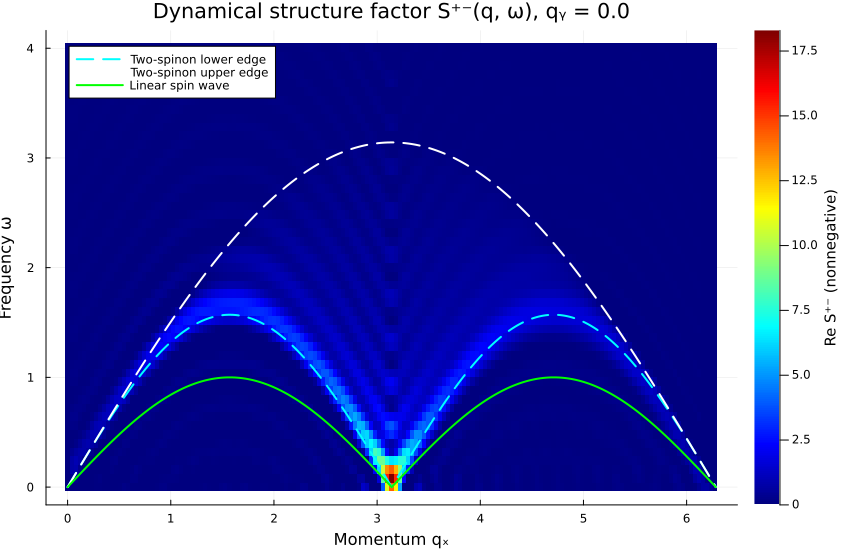

In [8]:
omega_max_plot = 4.0
sqw_real = real.(sqw)
sqw_positive = max.(sqw_real, 0.0)
color_max = maximum(sqw_positive)
sqw_plot = heatmap(
    qx_values,
    omega_values,
    permutedims(sqw_positive);
    xlabel="Momentum qₓ",
    ylabel="Frequency ω",
    title="Dynamical structure factor S⁺⁻(q, ω), qᵧ = $qy",
    colorbar_title="Re S⁺⁻ (nonnegative)",
    c=:jet,
    clims=(0.0, color_max),
    interpolate=false,
    size=(850, 550),
)

plot!(sqw_plot, q_analytic, omega_two_spinon_lower; label="Two-spinon lower edge", color=:cyan, linestyle=:dash, linewidth=2)
plot!(sqw_plot, q_analytic, omega_two_spinon_upper; label="Two-spinon upper edge", color=:white, linestyle=:dash, linewidth=2)
plot!(sqw_plot, q_analytic, omega_spin_wave; label="Linear spin wave", color=:lime, linewidth=2)

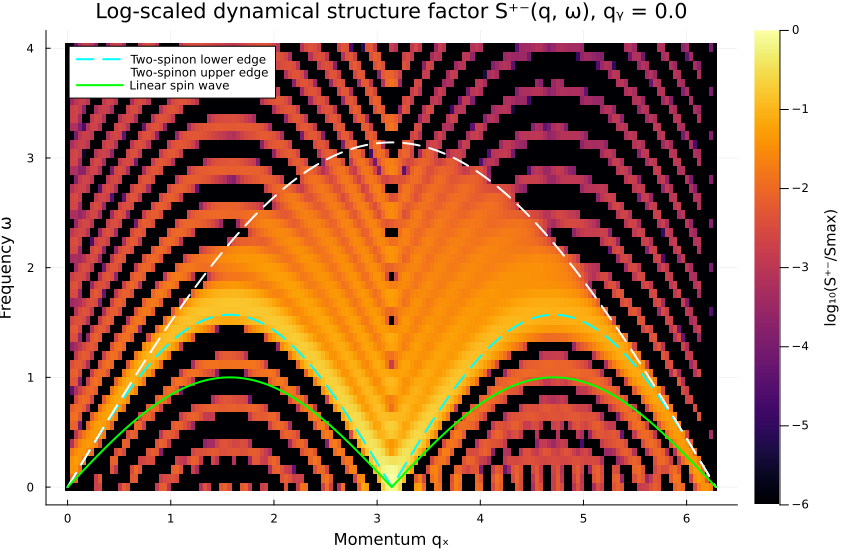

In [9]:
# Repeat the unsmoothed plot with intensity normalized to its maximum and shown on a log scale.
log_floor = 1e-6
sqw_normalized = sqw_positive ./ color_max
sqw_log = log10.(max.(sqw_normalized, log_floor))

log_sqw_plot = heatmap(
    qx_values,
    omega_values,
    permutedims(sqw_log);
    xlabel="Momentum qₓ",
    ylabel="Frequency ω",
    title="Log-scaled dynamical structure factor S⁺⁻(q, ω), qᵧ = $qy",
    colorbar_title="log₁₀(S⁺⁻/Smax)",
    c=:inferno,
    clims=(log10(log_floor), 0.0),
    interpolate=false,
    size=(850, 550),
)

plot!(log_sqw_plot, q_analytic, omega_two_spinon_lower; label="Two-spinon lower edge", color=:cyan, linestyle=:dash, linewidth=2)
plot!(log_sqw_plot, q_analytic, omega_two_spinon_upper; label="Two-spinon upper edge", color=:white, linestyle=:dash, linewidth=2)
plot!(log_sqw_plot, q_analytic, omega_spin_wave; label="Linear spin wave", color=:lime, linewidth=2)
display(log_sqw_plot)

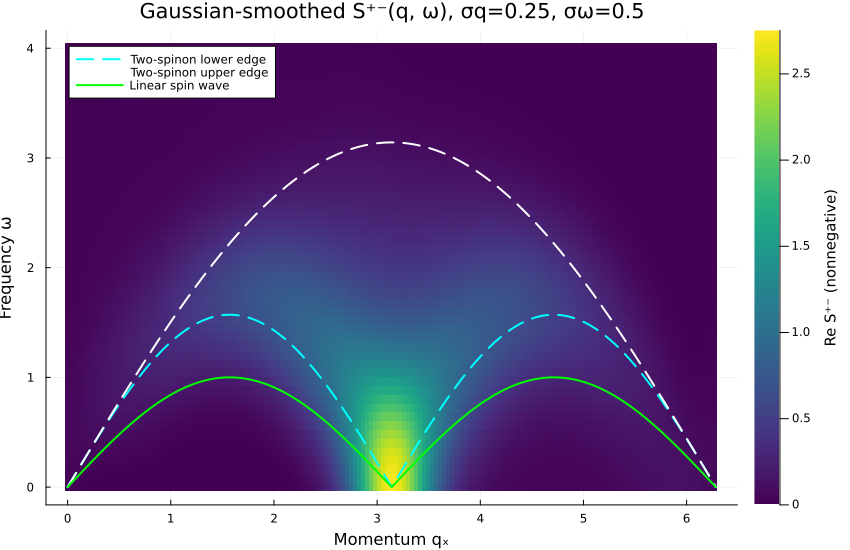

In [10]:
# Optional Gaussian smoothing for visualization; the preceding heatmap remains unsmoothed.
# These widths are in momentum/frequency units, not grid points.
sigma_q = 0.25
sigma_omega = 0.5

function gaussian_kernel(sigma, spacing)
    radius = ceil(Int, 4 * sigma / spacing)
    offsets = collect(-radius:radius) .* spacing
    weights = exp.(-0.5 .* (offsets ./ sigma).^2)
    return weights ./ sum(weights)
end

function gaussian_filter_axis(data, kernel, axis)
    filtered = similar(data)
    radius = div(length(kernel), 2)
    nq, nw = size(data)

    for iq in 1:nq, iw in 1:nw
        value = 0.0
        for offset in -radius:radius
            weight = kernel[offset + radius + 1]
            if axis == 1
                source_q = mod1(iq + offset, nq)
                value += weight * data[source_q, iw]
            else
                source_w = clamp(iw + offset, 1, nw)
                value += weight * data[iq, source_w]
            end
        end
        filtered[iq, iw] = value
    end
    return filtered
end

q_kernel = gaussian_kernel(sigma_q, qx_values[2] - qx_values[1])
omega_kernel = gaussian_kernel(sigma_omega, omega_values[2] - omega_values[1])
sqw_smoothed = gaussian_filter_axis(sqw_real, q_kernel, 1)
sqw_smoothed = gaussian_filter_axis(sqw_smoothed, omega_kernel, 2)
sqw_smoothed_positive = max.(sqw_smoothed, 0.0)
smooth_color_max = maximum(sqw_smoothed_positive)

smooth_plot = heatmap(
    qx_values,
    omega_values,
    permutedims(sqw_smoothed_positive);
    xlabel="Momentum qₓ",
    ylabel="Frequency ω",
    title="Gaussian-smoothed S⁺⁻(q, ω), σq=$sigma_q, σω=$sigma_omega",
    colorbar_title="Re S⁺⁻ (nonnegative)",
    c=:viridis,
    clims=(0.0, smooth_color_max),
    interpolate=false,
    size=(850, 550),
)

plot!(smooth_plot, q_analytic, omega_two_spinon_lower; label="Two-spinon lower edge", color=:cyan, linestyle=:dash, linewidth=2)
plot!(smooth_plot, q_analytic, omega_two_spinon_upper; label="Two-spinon upper edge", color=:white, linestyle=:dash, linewidth=2)
plot!(smooth_plot, q_analytic, omega_spin_wave; label="Linear spin wave", color=:lime, linewidth=2)

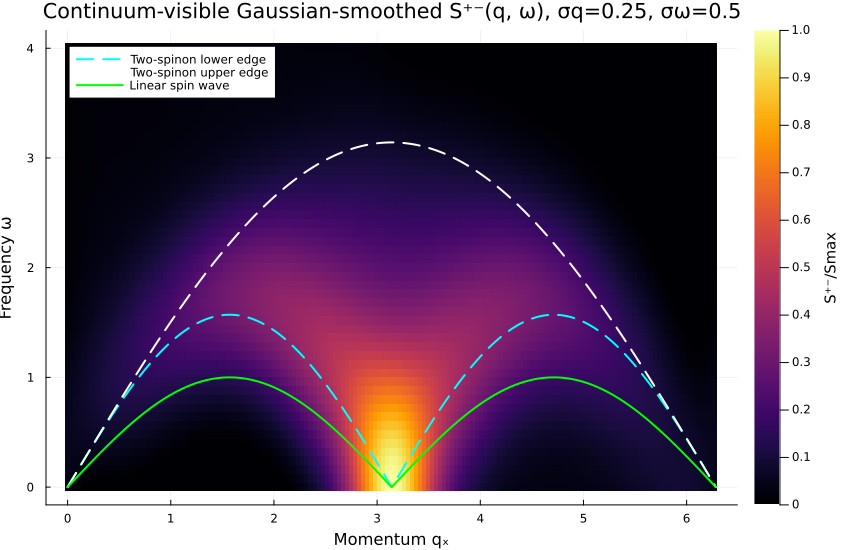

In [11]:
# A sublinear power mapping keeps the continuum visible while preserving contrast in this additional view.
smooth_intensity_gamma = 0.75
sqw_smoothed_normalized = sqw_smoothed_positive ./ smooth_color_max
sqw_smoothed_contrast = sqw_smoothed_normalized .^ smooth_intensity_gamma
intensity_ticks = 0.0:0.25:1.0

smooth_contrast_plot = heatmap(
    qx_values,
    omega_values,
    permutedims(sqw_smoothed_contrast);
    xlabel="Momentum qₓ",
    ylabel="Frequency ω",
    title="Continuum-visible Gaussian-smoothed S⁺⁻(q, ω), σq=$sigma_q, σω=$sigma_omega",
    colorbar_title="S⁺⁻/Smax",
    colorbar_ticks=(intensity_ticks .^ smooth_intensity_gamma, string.(intensity_ticks)),
    c=:inferno,
    clims=(0.0, 1.0),
    interpolate=false,
    size=(850, 550),
)

plot!(smooth_contrast_plot, q_analytic, omega_two_spinon_lower; label="Two-spinon lower edge", color=:cyan, linestyle=:dash, linewidth=2)
plot!(smooth_contrast_plot, q_analytic, omega_two_spinon_upper; label="Two-spinon upper edge", color=:white, linestyle=:dash, linewidth=2)
plot!(smooth_contrast_plot, q_analytic, omega_spin_wave; label="Linear spin wave", color=:lime, linewidth=2)
display(smooth_contrast_plot)

In [12]:
figure_dir = joinpath("results", "figures")
mkpath(figure_dir)
savefig(sqw_plot, joinpath(figure_dir, "sqw_linear.png"))
savefig(log_sqw_plot, joinpath(figure_dir, "sqw_log.png"))
savefig(smooth_plot, joinpath(figure_dir, "sqw_smoothed_linear.png"))
savefig(smooth_contrast_plot, joinpath(figure_dir, "sqw_smoothed_contrast.png"))
println("Saved structure-factor figures to $figure_dir")

Saved structure-factor figures to results/figures
